In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

D_ALL = pd.read_csv("../data/processed/data_with_flags.csv")
INPUTS  = ["ecc", "N", "gammaG", "Esoil", "Econc", "Dbot", "H1", "H2", "H3"]
OUTPUTS = ["Mr_t", "Mt_t", "Mr_c", "Mt_c"]
D_ALL["suspect_row"] = D_ALL["suspect_row"].astype(bool)

# Main analysis: leave out the 2 suspect rows and rows with ecc = 0 (a moment of N*ecc = 0 predicts 0).
d = D_ALL[~D_ALL.suspect_row].copy()
z = d[d.ecc > 0].copy()
print("all rows:", len(D_ALL), "| without suspect rows:", len(d), "| used (ecc > 0):", len(z))
Path("../figures").mkdir(exist_ok=True)

all rows: 5184 | without suspect rows: 5182 | used (ecc > 0): 3886




`fit_k` finds the single scale factor `k` that best matches `result = k * x` (least squares through the origin).
`scores` reports how close the hand value is to the FEM value.

In [2]:
def fit_k(y, x):
    return float((y * x).sum() / (x * x).sum())

def scores(y, yhat):
    rel = (y - yhat).abs() / y.abs()
    ss_res = ((y - yhat) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    return {
        "R2": 1 - ss_res / ss_tot,
        "median_%err": 100 * rel.median(),
        "within_10%": 100 * (rel <= 0.10).mean(),
        "within_20%": 100 * (rel <= 0.20).mean(),
        "spearman": y.corr(yhat, method="spearman"),
    }

 2.Candidate A: result = k * N * ecc

The overturning moment is `N * ecc`. If the FEM results are driven by it, one constant per result should predict them.

In [3]:
z["x_A"] = z.N * z.ecc
rowsA, kA = [], {}
for o in OUTPUTS:
    k = fit_k(z[o], z.x_A)
    kA[o] = k
    z[f"A_{o}"] = k * z.x_A
    rowsA.append({"result": o, "k": k, **scores(z[o], z[f"A_{o}"])})
resA = pd.DataFrame(rowsA).set_index("result")
resA.assign(k=resA.k.map("{:.2e}".format)).round(3)

,k,R2,median_%err,within_10%,within_20%,spearman
result,,,,,,
Mr_t,-3.35e-05,0.804,17.654,28.049,56.794,0.930
Mt_t,-1.85e-05,0.947,11.352,45.214,63.922,0.975
Mr_c,5.71e-05,0.966,8.687,56.202,81.498,0.938
Mt_c,3.07e-05,0.944,9.206,53.397,82.398,0.934


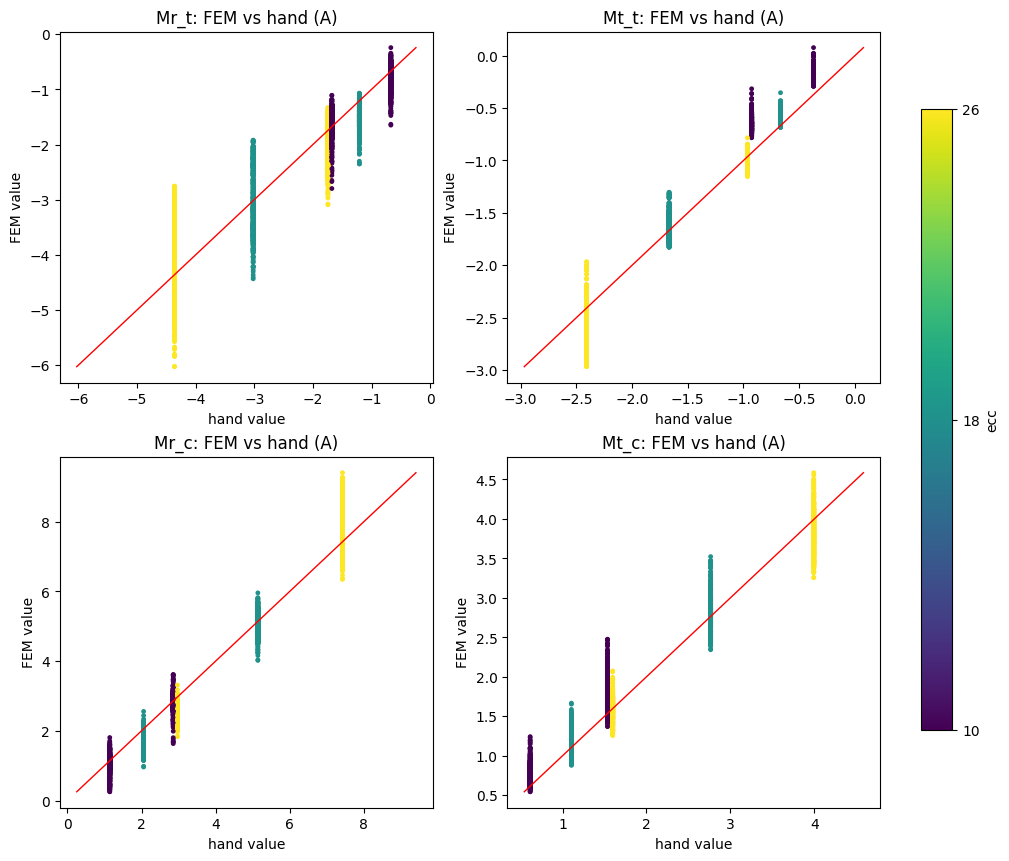

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5), layout="constrained")
for ax, o in zip(axes.ravel(), OUTPUTS):
    sc = ax.scatter(z[f"A_{o}"], z[o], c=z.ecc, cmap="viridis", s=6)
    lim = [min(z[o].min(), z[f"A_{o}"].min()), max(z[o].max(), z[f"A_{o}"].max())]
    ax.plot(lim, lim, color="red", lw=1)
    ax.set_title(f"{o}: FEM vs hand (A)"); ax.set_xlabel("hand value"); ax.set_ylabel("FEM value")
fig.colorbar(sc, ax=axes, label="ecc", shrink=0.8, ticks=[10, 18, 26])
plt.savefig("../figures/05_fem_vs_hand_A.png", dpi=150, bbox_inches="tight")
plt.show()

A perfect formula would put every point on the red line. Points far from it are runs where the formula fails.

 3. Where does candidate A fail?

For each input level, the median percent error. Large numbers show which settings break the formula.

In [5]:
rows = []
for o in OUTPUTS:
    z[f"err_{o}"] = 100 * (z[o] - z[f"A_{o}"]).abs() / z[o].abs()
for inp in INPUTS:
    g = z.groupby(inp)[[f"err_{o}" for o in OUTPUTS]].median().round(1)
    g.columns = OUTPUTS
    g.insert(0, "input", inp)
    rows.append(g.reset_index().rename(columns={inp: "level"}))
err_by_level = pd.concat(rows, ignore_index=True)
err_by_level

,level,input,Mr_t,Mt_t,Mr_c,Mt_c
0,10.0,ecc,15.4,53.5,8.3,19.1
1,18.0,ecc,18.3,7.6,7.5,7.2
2,26.0,ecc,18.3,6.4,9.8,6.0
3,2000.0,N,21.6,12.3,14.4,10.7
4,5000.0,N,13.7,10.4,4.7,8.0
5,0.9,gammaG,17.0,11.6,8.3,9.1
6,1.1,gammaG,18.2,11.2,9.2,9.4
7,25.0,Esoil,15.1,11.5,6.1,8.8
8,75.0,Esoil,20.5,11.3,11.7,9.5
9,30000.0,Econc,17.6,11.3,8.8,9.2


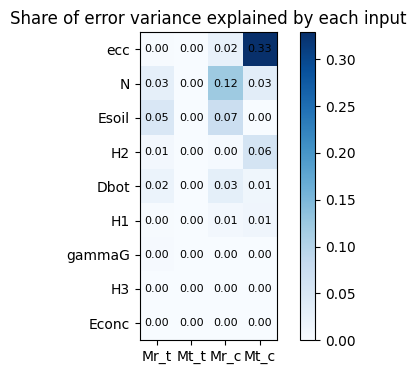

,Mr_t,Mt_t,Mr_c,Mt_c
ecc,0.001,0.001,0.025,0.329
N,0.029,0.000,0.122,0.034
Esoil,0.050,0.000,0.074,0.000
H2,0.009,0.001,0.004,0.057
Dbot,0.020,0.001,0.031,0.012
H1,0.002,0.001,0.008,0.014
gammaG,0.003,0.000,0.001,0.000
H3,0.000,0.001,0.000,0.001
Econc,0.000,0.000,0.000,0.000


In [6]:
# Which input explains the error most? eta^2 = share of error variance explained by grouping on that input.
def eta2(err, by):
    gm = err.mean()
    ss_b = z.groupby(by)[err.name].apply(lambda s: len(s) * (s.mean() - gm) ** 2).sum()
    return ss_b / ((err - gm) ** 2).sum()

eta = pd.DataFrame({o: {inp: eta2(z[f"err_{o}"], inp) for inp in INPUTS} for o in OUTPUTS})
eta = eta.loc[eta.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(eta.values, cmap="Blues", vmin=0)
ax.set_xticks(range(4)); ax.set_xticklabels(OUTPUTS)
ax.set_yticks(range(len(eta))); ax.set_yticklabels(eta.index)
for i in range(eta.shape[0]):
    for j in range(4):
        ax.text(j, i, f"{eta.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Share of error variance explained by each input")
plt.colorbar(im)
plt.savefig("../figures/05_error_drivers.png", dpi=150, bbox_inches="tight")
plt.show()
eta.round(3)

Inputs with high values are the ones that make the hand formula fail. This is the main result of the comparison.

 4. Candidate B: contact stress on a circular footing

Textbook statics: `q = N/A +/- M/W`, with `A = pi D^2 / 4`, `W = pi D^3 / 32` and `M = N * e`. This is equal to `(4N / (pi D^2)) * (1 +/- 8e/D)`. The extra pressure caused by the eccentricity is `dq = (4N / (pi D^2)) * (8e / D)`.

Because the scale factor `k` absorbs the units of `ecc`, this test does not depend on them.

In [7]:
z["x_B"] = (4 * z.N / (np.pi * z.Dbot**2)) * (8 * z.ecc / z.Dbot)
rowsB, kB = [], {}
for o in OUTPUTS:
    k = fit_k(z[o], z.x_B)
    kB[o] = k
    z[f"B_{o}"] = k * z.x_B
    rowsB.append({"result": o, "k": k, **scores(z[o], z[f"B_{o}"])})
resB = pd.DataFrame(rowsB).set_index("result")
compare = pd.concat({"A: k*N*ecc": resA[["R2", "median_%err", "within_20%"]],
                     "B: k*contact stress": resB[["R2", "median_%err", "within_20%"]]}, axis=1)
compare.round(3)

A: k*N*ecc                        B: k*contact stress              \
               R2 median_%err within_20%                  R2 median_%err   
result                                                                     
Mr_t        0.804      17.654     56.794              -0.156      45.793   
Mt_t        0.947      11.352     63.922               0.566      32.989   
Mr_c        0.966       8.687     81.498               0.661      37.409   
Mt_c        0.944       9.206     82.398               0.284      36.402   

                   
       within_20%  
result             
Mr_t       15.903  
Mt_t       23.263  
Mr_c       29.825  
Mt_c       19.480

Why B fits worse: the stress term contains `1 / D^3`, so it predicts large changes with the diameter `Dbot`. The next chart compares that prediction with the FEM results.

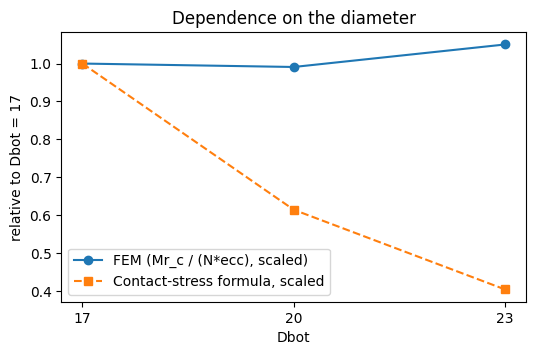

,FEM,contact stress
Dbot,,
17,1.000,1.000
20,0.991,0.614
23,1.050,0.404


In [8]:
g = z.assign(r=z.Mr_c / z.x_A).groupby("Dbot")["r"].mean()
fem_shape = g / g.iloc[0]
stress_shape = (z.groupby("Dbot")["x_B"].mean() / z.groupby("Dbot")["x_A"].mean())
stress_shape = stress_shape / stress_shape.iloc[0]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(fem_shape.index, fem_shape.values, "o-", label="FEM (Mr_c / (N*ecc), scaled)")
ax.plot(stress_shape.index, stress_shape.values, "s--", label="Contact-stress formula, scaled")
ax.set_xlabel("Dbot"); ax.set_ylabel("relative to Dbot = 17"); ax.legend(); ax.set_xticks(fem_shape.index)
ax.set_title("Dependence on the diameter")
plt.savefig("../figures/05_diameter_dependence.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame({"FEM": fem_shape, "contact stress": stress_shape}).round(3)

 5. Kern check: does the footing lift off?

The contact-stress formula holds only while `e <= D/8` (the whole base stays in compression). The unit of `ecc` is unknown, so this table shows the share of runs inside that limit for several unit guesses.

In [9]:
rows = []
for u, label in [(1, "ecc in the same unit as Dbot"), (0.1, "ecc / 10"), (0.01, "ecc / 100"), (0.001, "ecc / 1000")]:
    inside = ((z.ecc * u) <= z.Dbot / 8).mean() * 100
    rows.append({"unit factor u": u, "meaning": label, "% of runs with ecc*u <= D/8": round(inside, 1)})
pd.DataFrame(rows)

,unit factor u,meaning,% of runs with ecc*u <= D/8
0,1.000,ecc in the same unit as Dbot,0.0
1,0.100,ecc / 10,77.8
2,0.010,ecc / 100,100.0
3,0.001,ecc / 1000,100.0


If `ecc` has the same unit as `Dbot`, no eccentric run is inside the limit and lift-off would be present everywhere. The FEM results of `Mr_c` stay almost proportional to `ecc` (section 7), which suggests the limit is not exceeded. This is another reason to confirm the units with the author.

 6. Candidate C: empirical power law

`log|result| = a + b1*log(ecc) + b2*log(N) + b3*log(Dbot) + ...`. Each exponent shows how strongly the result scales with that input (an exponent of 1 means proportional, 0 means no effect).

In [10]:
cols = {"ecc": z.ecc, "N": z.N, "Dbot": z.Dbot, "H1": z.H1, "H2": z.H2, "H3": z.H3,
        "Esoil": z.Esoil, "Econc": z.Econc, "gammaG": z.gammaG}
X = pd.DataFrame({k: np.log(v) for k, v in cols.items()})
X.insert(0, "const", 1.0)
rows = {}
for o in OUTPUTS:
    y = np.log(z[o].abs())
    b = np.linalg.lstsq(X.values, y.values, rcond=None)[0]
    pred = X.values @ b
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    rows[o] = dict(zip(X.columns, b)) | {"R2 (log scale)": r2}
power = pd.DataFrame(rows).drop(index="const").round(3)
power

,Mr_t,Mt_t,Mr_c,Mt_c
ecc,0.987,1.601,1.036,0.740
N,0.741,1.157,1.178,0.947
Dbot,0.994,-0.175,0.201,0.327
H1,0.152,-0.097,-0.080,0.135
H2,0.209,-0.022,0.012,0.250
H3,0.034,0.153,-0.023,0.017
Esoil,0.039,0.006,-0.092,-0.014
Econc,-0.003,0.020,0.006,0.009
gammaG,0.225,-0.105,-0.116,0.038
R2 (log scale),0.946,0.934,0.956,0.992


Exponents near 1 for `ecc` and `N` support candidate A. Exponents near 0 for `Esoil`, `Econc` and `gammaG` agree with the effect sizes found earlier.

 7. Is the result proportional to ecc?

If the footing lifted off at high `ecc`, the ratio `result / (N * ecc)` would change with `ecc`. A constant ratio means the pattern is linear.

In [11]:
ratio = z.assign(**{o: z[o] / z.x_A * 1e5 for o in OUTPUTS}).groupby("ecc")[OUTPUTS].mean()
ratio.round(3)

,Mr_t,Mt_t,Mr_c,Mt_c
ecc,,,,
10,-3.707,-1.157,5.352,3.814
18,-3.807,-1.726,5.265,3.198
26,-3.621,-1.951,5.453,2.971


 8. What the hand calculation says about the two suspect rows

Rows 4377 and 4381 were flagged because `Mr_c` is near 0.1 while similar runs are 1.0 to 1.4. The hand calculation A was fitted without them, so it is an independent check.

In [12]:
s = D_ALL[D_ALL.suspect_row].copy()
s["hand_Mr_c"] = kA["Mr_c"] * s.N * s.ecc
s["FEM_Mr_c"] = s["Mr_c"]
s["FEM / hand"] = s.FEM_Mr_c / s.hand_Mr_c
sib = z[(z.ecc == 10) & (z.N == 2000) & (z.Dbot == 23) & (z.H1 == 1.2) & (z.H2 == 1.5) & (z.H3 == 1.6)]
print("Hand value (A) for the suspect rows vs FEM:")
display(s[["ecc", "N", "Econc", "hand_Mr_c", "FEM_Mr_c", "FEM / hand"]].round(3))
print("Similar runs (same geometry and load): FEM Mr_c from", sib.Mr_c.min().round(3), "to", sib.Mr_c.max().round(3),
      "| hand value", round(kA["Mr_c"] * 2000 * 10, 3))

Hand value (A) for the suspect rows vs FEM:


,ecc,N,Econc,hand_Mr_c,FEM_Mr_c,FEM / hand
4377,10,2000,30000,1.142,0.105,0.092
4381,10,2000,37000,1.142,0.080,0.070


Similar runs (same geometry and load): FEM Mr_c from 1.03 to 1.393 | hand value 1.142


If the hand value is near 1 and the FEM values are near 0.1, the hand calculation supports the idea that the two rows are simulation errors. It does not prove it.

 9. Summary and saved results

In [13]:
print("Candidate A (k * N * ecc), all four results:")
display(resA.assign(k=resA.k.map("{:.2e}".format)).round(3))
print("Candidate B (contact stress):")
display(resB.assign(k=resB.k.map("{:.2e}".format)).round(3))

keep = ["ecc", "N", "Dbot", "H1", "H2", "H3", "Esoil", "Econc", "gammaG"] + OUTPUTS + \
       [f"A_{o}" for o in OUTPUTS] + [f"B_{o}" for o in OUTPUTS] + [f"err_{o}" for o in OUTPUTS]
z[keep].to_csv("../data/processed/hand_calc_results.csv")
print("saved ../data/processed/hand_calc_results.csv", z[keep].shape)

Candidate A (k * N * ecc), all four results:


,k,R2,median_%err,within_10%,within_20%,spearman
result,,,,,,
Mr_t,-3.35e-05,0.804,17.654,28.049,56.794,0.930
Mt_t,-1.85e-05,0.947,11.352,45.214,63.922,0.975
Mr_c,5.71e-05,0.966,8.687,56.202,81.498,0.938
Mt_c,3.07e-05,0.944,9.206,53.397,82.398,0.934


Candidate B (contact stress):


,k,R2,median_%err,within_10%,within_20%,spearman
result,,,,,,
Mr_t,-1.99e-02,-0.156,45.793,5.121,15.903,0.702
Mt_t,-1.16e-02,0.566,32.989,7.102,23.263,0.854
Mr_c,3.66e-02,0.661,37.409,11.245,29.825,0.828
Mt_c,1.91e-02,0.284,36.402,6.330,19.480,0.797


saved ../data/processed/hand_calc_results.csv (3886, 25)


 Conclusions (numbers from the run on the current data; rerun the notebook if the data changes)

1. **Candidate A (`k * N * ecc`) is a reasonable first hand calculation.** R2 is 0.94 to 0.97 for `Mt_t`, `Mr_c` and `Mt_c`, and 0.80 for `Mr_t`. The median error is 9% to 18%, and 57% to 82% of runs are within 20%.
2. **The contact-stress formula (candidate B) fits much worse.** Its median error is 33% to 46%. The main reason: from `Dbot` 17 to 23 the FEM ratio changes by at most 5%, while the stress formula predicts a drop of about 60%.
3. **Candidate A fails mostly in three places.**
   - Tangential moments at low eccentricity: `Mt_t` has a median error of 53% at `ecc` 10, against 6% to 8% at `ecc` 18 and 26. `Mt_c` has 19% at `ecc` 10, against 6% to 7%.
   - Low load: `Mr_c` has a median error of 14% at `N` 2000, against 5% at `N` 5000.
   - Soil stiffness: `Mr_c` has 12% at `Esoil` 75, against 6% at `Esoil` 25.
4. **The hand value for the two suspect rows is about 1.14, while FEM gives 0.105 and 0.080.** Similar runs have FEM values of 1.03 to 1.39. This supports the idea that rows 4377 and 4381 are simulation errors, but it does not prove it.